In [1]:
import os
import json
import ast
from typing import TypedDict, Any

from dotenv import load_dotenv
from langchain_community.tools.tavily_search import TavilySearchResults
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage, ToolMessage
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.graph import StateGraph, START, END

load_dotenv("config.env", override=True)

GOOGLE_API_KEY = os.getenv("GOOGLE_API_KEY")
TAVILY_API_KEY = os.getenv("TAVILY_API_KEY")

assert GOOGLE_API_KEY, "GOOGLE_API_KEY is missing from config.env"
assert TAVILY_API_KEY, "TAVILY_API_KEY is missing from config.env"

print("API configuration loaded successfully.")


C:\Users\himan\AppData\Local\Temp\ipykernel_13008\2152189067.py:7: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools.tavily_search import TavilySearchResults


API configuration loaded successfully.


In [2]:
llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    google_api_key=GOOGLE_API_KEY,
    max_output_tokens=1024
)

tavily_search = TavilySearchResults(
    max_results=3,
    search_depth="basic",
    include_answer=False,
    include_raw_content=False,
    tavily_api_key=TAVILY_API_KEY
)

search_llm = llm.bind_tools(
    [tavily_search],
    tool_choice="any"
)

print("Gemini and Tavily initialized successfully.")


Gemini and Tavily initialized successfully.


C:\Users\himan\AppData\Local\Temp\ipykernel_13008\1363782541.py:7: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tavily_search = TavilySearchResults(


In [3]:
class HealthBotState(TypedDict):   # here we are doing--
    messages: list[BaseMessage]
    topic: str
    search_call: Any
    sources: list[dict]
    summary: str
    ready: bool
    question: str
    expected_points: list[str]
    patient_answer: str
    grade: str
    explanation: str
    citation: str
    next_step: str


def new_session_state() -> HealthBotState:
    """Return a completely independent state for a new topic."""
    return {
        "messages": [],
        "topic": "",
        "search_call": None,
        "sources": [],
        "summary": "",
        "ready": False,
        "question": "",
        "expected_points": [],
        "patient_answer": "",
        "grade": "",
        "explanation": "",
        "citation": "",
        "next_step": ""
    }


print("Shared state schema created.")


Shared state schema created.


In [4]:
SUMMARY_PROMPT = """
You are a careful patient educator. Use ONLY the numbered Tavily sources below.

Create exactly THREE short, patient-friendly paragraphs:
1. Explain what the health topic is and its important causes or effects.
2. Explain important symptoms or warning signs mentioned in the sources.
3. Explain management, prevention, or treatment from the sources and advise
   consulting a qualified healthcare professional.

Rules:
- Each paragraph must be 35-55 words.
- Do not diagnose the patient or prescribe medication.
- Do not use facts that are absent from the sources.
- Every paragraph must contain at least one citation such as [Source 1].
- Return valid JSON only, without Markdown fences.

Return exactly this structure:
{{"paragraphs":["First paragraph", "Second paragraph", "Third paragraph"]}}

NUMBERED TAVILY SOURCES:
{source_text}
"""

QUESTION_PROMPT = """
Using ONLY the patient summary below, create exactly ONE short-answer
comprehension question. The question must be answerable from the summary alone.
Also list 2-4 short expected points used to assess the answer.

Return valid JSON only:
{{"question":"...","expected_points":["...","..."]}}

PATIENT SUMMARY:
{summary}
"""

GRADING_PROMPT = """
Evaluate the patient's answer using ONLY the supplied summary, question, and
expected points. Do not use outside medical knowledge.

Grade scale:
- A: correct and complete
- B: mostly correct with a minor omission
- C: partially correct with important omissions
- D: minimally correct but still relevant
- F: incorrect, unrelated, or unsupported

Provide a short explanation and a relevant statement from the summary that
contains an existing [Source N] citation. Never invent a citation.
Return valid JSON only:
{{"grade":"A","explanation":"...","citation":"... [Source 1]"}}

SUMMARY: {summary}
QUESTION: {question}
EXPECTED POINTS: {expected_points}
PATIENT ANSWER: {patient_answer}
"""


In [5]:
def clean_json_response(content: Any) -> dict:
    """Parse JSON and tolerate accidental Markdown code fences."""
    if isinstance(content, list):
        content = "".join(
            str(part.get("text", "")) if isinstance(part, dict) else str(part)
            for part in content
        )
    text = str(content).strip()
    if text.startswith("```json"):
        text = text[7:]
    elif text.startswith("```"):
        text = text[3:]
    if text.endswith("```"):
        text = text[:-3]
    return json.loads(text.strip())

In [6]:
def normalize_search_results(raw: Any) -> list[dict]:
    """Normalize Tavily tuple, JSON string, dictionary, or list output."""
    if isinstance(raw, tuple):
        raw = raw[1]

    if isinstance(raw, str):
        try:
            raw = json.loads(raw)
        except json.JSONDecodeError:
            try:
                raw = ast.literal_eval(raw)
            except (ValueError, SyntaxError) as exc:
                raise RuntimeError(f"Tavily returned an error instead of results: {raw}") from exc

    if isinstance(raw, dict):
        raw = raw.get("results", [raw])

    if not isinstance(raw, list):
        raise TypeError(f"Unexpected Tavily response type: {type(raw).__name__}")

    results = [
        item for item in raw
        if isinstance(item, dict) and item.get("content") and item.get("url")
    ]
    if not results:
        raise RuntimeError("Tavily returned no usable medical sources.")
    return results

In [7]:

def source_context(results: list[dict]) -> str:
    """Create numbered source blocks for grounded summarization."""
    blocks = []
    for number, item in enumerate(results, start=1):
        blocks.append(
            f"[Source {number}]\n"
            f"Title: {item.get('title', 'Medical source')}\n"
            # f"URL: {item.get('url', '')}\n"
            # f"Retrieved content: {item.get('content', '')}"
        )
    return "\n\n".join(blocks)

In [8]:
def collect_topic_node(state: HealthBotState) -> dict: # here we taking input from user and thses are nodes to discribe to particuler topic
    print("\n" + "=" * 64)
    print("HEALTHBRIDGE - PATIENT EDUCATION")
    print("Educational information only; not personal medical advice.")
    print("=" * 64)

    topic = input("What health topic would you like to learn about?\n> ").strip()
    while not topic:
        topic = input("Please enter a non-empty health topic:\n> ").strip()

    print(f"Selected topic: {topic}")

    topic_message = HumanMessage(content=f"The patient selected this topic: {topic}")
    return {"topic": topic, "messages": [topic_message]}

In [9]:
def create_search_call_node(state: HealthBotState) -> dict:
    """Make gemini create a Tavily tool call for the selected topic."""
    instruction = HumanMessage(content=(
        f"Call Tavily once for current, patient-friendly information about "
        f"'{state['topic']}'. Prefer government health agencies, major hospitals, "
        "and recognized medical organizations."
    ))
    model_message = search_llm.invoke(state["messages"] + [instruction])
    if not model_message.tool_calls:
        raise RuntimeError("OpenAI did not produce the required Tavily tool call.")

    return {
        "search_call": model_message.tool_calls[0],
        "messages": state["messages"] + [instruction, model_message]
    }

In [10]:
def execute_search_node(state: HealthBotState) -> dict:
    """Execute the exact Tavily call created by gemini."""
    print("\nSearching reputable medical sources...")
    call = state["search_call"]
    raw_results = tavily_search.invoke(call["args"])
    sources = normalize_search_results(raw_results)

    tool_message = ToolMessage(
        content=json.dumps(sources, ensure_ascii=False),
        tool_call_id=call["id"]
    )
    print(f"Search completed: {len(sources)} source(s) retrieved.")
    return {
        "sources": sources,
        "messages": state["messages"] + [tool_message]
    }


In [11]:
def generate_summary_node(state: HealthBotState) -> dict:
    """Create a compact three-paragraph summary from Tavily evidence only."""
    print("Creating a short patient-friendly summary...")

    prompt = SUMMARY_PROMPT.format(
        source_text=source_context(state["sources"])
    )
    model_message = llm.invoke(prompt)
    data = clean_json_response(model_message.content)
    paragraphs = data.get("paragraphs", [])

    if not isinstance(paragraphs, list) or len(paragraphs) != 3:
        raise RuntimeError("Gemini did not return exactly three summary paragraphs.")

    paragraphs = [str(paragraph).strip() for paragraph in paragraphs]
    if any(not paragraph for paragraph in paragraphs):
        raise RuntimeError("Gemini returned an empty summary paragraph.")

    for number, paragraph in enumerate(paragraphs, start=1):
        if "[Source " not in paragraph:
            raise RuntimeError(
                f"Summary paragraph {number} does not contain a source citation."
            )

    summary = "\n\n".join(paragraphs)
    print("Summary completed: 3 short paragraphs created.")

    return {
        "summary": summary,
        "messages": state["messages"] + [AIMessage(content=summary)]
    }

In [12]:
def present_summary_node(state: HealthBotState) -> dict:
    print("\n" + "-" * 64)
    print(f"PATIENT SUMMARY: {state['topic'].upper()}")
    print("-" * 64)
    print(state["summary"])
    # print("\nRetrieved sources:")
    # for number, item in enumerate(state["sources"], start=1):
    #     print(f"[Source {number}] {item.get('title', 'Medical source')}")
    #     print(f"  {item.get('url', '')}")

    input("\nRead the summary above, then press ENTER for the comprehension check...")
    return {"ready": True}

In [13]:
def generate_question_node(state: HealthBotState) -> dict:
    model_message = llm.invoke(QUESTION_PROMPT.format(summary=state["summary"]))
    data = clean_json_response(model_message.content)
    question = str(data.get("question", "")).strip()
    expected_points = data.get("expected_points", [])

    if not question or not isinstance(expected_points, list) or not expected_points:
        raise RuntimeError("The model returned an incomplete comprehension question.")

    history_message = AIMessage(content=json.dumps({
        "question": question,
        "expected_points": expected_points
    }))
    return {
        "question": question,     
        "expected_points": [str(point) for point in expected_points],
        "messages": state["messages"] + [history_message]
    }

In [14]:
def collect_answer_node(state: HealthBotState) -> dict:
    print("\nCOMPREHENSION CHECK")
    print(state["question"])
    answer = input("> ").strip()
    while not answer:
        answer = input("Please enter a non-empty answer:\n> ").strip()

    answer_message = HumanMessage(content=f"Patient quiz answer: {answer}")
    return {
        "patient_answer": answer,
        "messages": state["messages"] + [answer_message]
    }

In [15]:
def grade_answer_node(state: HealthBotState) -> dict:
    model_message = llm.invoke(GRADING_PROMPT.format(
        summary=state["summary"],
        question=state["question"],
        expected_points=json.dumps(state["expected_points"]),
        patient_answer=state["patient_answer"]
    ))
    data = clean_json_response(model_message.content)

    grade = str(data.get("grade", "")).strip().upper()
    explanation = str(data.get("explanation", "")).strip()
    citation = str(data.get("citation", "")).strip()

    if grade not in {"A", "B", "C", "D", "F"}:
        raise RuntimeError("The model returned an invalid grade.")
    if not explanation:
        raise RuntimeError("The grading explanation is missing.")
    if "[Source " not in citation:
        raise RuntimeError("The grading feedback is missing a valid summary citation.")

    feedback_message = AIMessage(content=(
        f"Grade: {grade}\nExplanation: {explanation}\nCitation: {citation}"
    ))
    return {
        "grade": grade,
        "explanation": explanation,
        "citation": citation,
        "messages": state["messages"] + [feedback_message]
    }

In [16]:
def present_feedback_node(state: HealthBotState) -> dict:
    print("\n" + "=" * 64)
    print(f"GRADE: {state['grade']}")
    print(f"EXPLANATION: {state['explanation']}")
    print(f"SUPPORTING CITATION: {state['citation']}")
    print("=" * 64)

    while True:
        choice = input("Learn another health topic? (yes/no):\n> ").strip().lower()
        if choice in {"yes", "no"}:
            return {"next_step": choice}
        print("Please enter yes or no.")

In [17]:
def reset_state_node(state: HealthBotState) -> HealthBotState:
    """Clear every field before a different health topic."""
    print("\nClearing the previous topic and starting a private new session...")
    return new_session_state()

In [18]:
def route_after_feedback(state: HealthBotState) -> str:
    return "reset" if state["next_step"] == "yes" else "exit"

In [19]:
builder = StateGraph(HealthBotState) #it is package, build nodes and edges 

builder.add_node("collect_topic", collect_topic_node) #here builder create all nodes 
builder.add_node("create_search_call", create_search_call_node)
builder.add_node("execute_search", execute_search_node)
builder.add_node("generate_summary", generate_summary_node)
builder.add_node("present_summary", present_summary_node)
builder.add_node("generate_question", generate_question_node)
builder.add_node("collect_answer", collect_answer_node)
builder.add_node("grade_answer", grade_answer_node)
builder.add_node("present_feedback", present_feedback_node)
builder.add_node("reset_state", reset_state_node)

builder.add_edge(START, "collect_topic")
builder.add_edge("collect_topic", "create_search_call")
builder.add_edge("create_search_call", "execute_search")
builder.add_edge("execute_search", "generate_summary")
builder.add_edge("generate_summary", "present_summary")
builder.add_edge("present_summary", "generate_question")
builder.add_edge("generate_question", "collect_answer")
builder.add_edge("collect_answer", "grade_answer")
builder.add_edge("grade_answer", "present_feedback")

builder.add_conditional_edges(
    "present_feedback",
    route_after_feedback,
    {"reset": "reset_state", "exit": END}
)
builder.add_edge("reset_state", "collect_topic")

healthbridge = builder.compile()
print("HealthBridge LangGraph compiled successfully.")


HealthBridge LangGraph compiled successfully.


In [21]:
# print(healthbridge.get_graph().draw_mermaid())


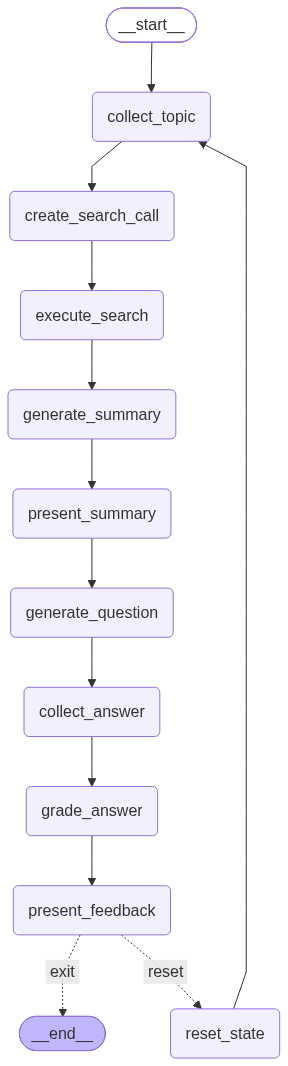

HealthBridge workflow graph displayed successfully.


In [22]:
from IPython.display import Image, display

try:
    graph_image = healthbridge.get_graph().draw_mermaid_png()

    display(
        Image(graph_image)
    )

    print("HealthBridge workflow graph displayed successfully.")

except Exception as error:
    print("Could not display the graph image.")
    print("Error type:", type(error).__name__)
    print("Error message:", error)

In [23]:
try:
    final_state = healthbridge.invoke(
        new_session_state(),
        config={"recursion_limit": 100}
    )
    print("\nHealthBridge session completed. Stay informed and stay healthy.")
except KeyboardInterrupt:
    print("\nThe patient stopped the session.")
except Exception as error:
    print("\nHealthBridge could not continue.")
    print("Error type:", type(error).__name__)
    print("Error message:", error)



HEALTHBRIDGE - PATIENT EDUCATION
Educational information only; not personal medical advice.
Selected topic: diabetes

Searching reputable medical sources...


Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


Search completed: 3 source(s) retrieved.
Creating a short patient-friendly summary...
Summary completed: 3 short paragraphs created.

----------------------------------------------------------------
PATIENT SUMMARY: DIABETES
----------------------------------------------------------------
Diabetes is a chronic health condition affecting how your body turns food into energy. Most of the food you eat is broken down into sugar and released into your bloodstream, which can cause significant health effects if improperly managed [Source 1].

Important warning signs and symptoms of this condition often include feeling very thirsty, urinating frequently, extreme fatigue, blurry vision, and unexplained weight loss. Recognizing these early signals is crucial for seeking timely medical evaluation and care [Source 1].

Management and prevention strategies involve healthy lifestyle habits, monitoring blood sugar levels, and specialized medical care. Because approaches vary, you should always consul

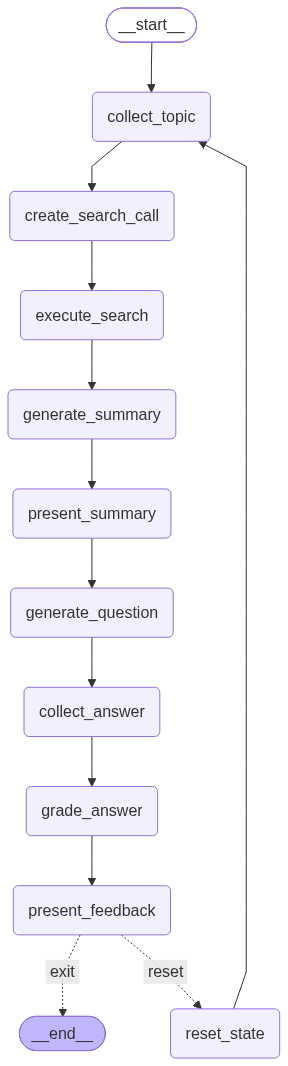

In [24]:
healthbridge